# Boston Dataset

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_graphviz
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report,mean_absolute_error,mean_squared_error,r2_score
from sklearn import tree

from IPython.display import Image

In [4]:
boston=pd.read_csv("D:\Machine Learning\Datasets\Boston.csv")
boston

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48,22.0


In [5]:
X=boston.drop('medv',axis=1)
y=boston['medv']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:

from tqdm import tqdm


depths = [None, 3, 4, 5, 6, 7]
min_samples = [0.01, 2, 10, 50, 100, 250]
min_leafs = [1, 10, 50, 100, 250]
scores = []
for depth in tqdm(depths):
    for min_sample in min_samples:
        for min_leaf in min_leafs:
            dtr = DecisionTreeRegressor(max_depth=depth, 
                                         min_samples_split=min_sample, 
                                         min_samples_leaf=min_leaf, 
                                         random_state=25)
            dtr.fit(X_train, y_train)
            y_pred = dtr.predict(X_test)
            scores.append([depth, min_sample, min_leaf, mean_absolute_error(y_test, y_pred),
                           mean_squared_error(y_test, y_pred),r2_score(y_test, y_pred)])
df_scores = pd.DataFrame(scores, columns=["max_depth", "min_samples_split", "min_samples_leaf", "MSE","MAE","R2_score"])
df_scores.sort_values("MSE")

100%|██████████| 6/6 [00:00<00:00,  7.78it/s]


,max_depth,min_samples_split,min_samples_leaf,MSE,MAE,R2_score
155,7.0,2.00,1,2.177242,8.540248,0.883543
160,7.0,10.00,1,2.187726,8.758679,0.880564
95,5.0,2.00,1,2.290510,8.423318,0.885137
150,7.0,0.01,1,2.338435,9.762874,0.866871
10,NaN,10.00,1,2.369883,10.003927,0.863584
...,...,...,...,...,...,...
149,6.0,250.00,250,6.255844,75.045430,-0.023341
174,7.0,100.00,250,6.255844,75.045430,-0.023341
169,7.0,50.00,250,6.255844,75.045430,-0.023341
164,7.0,10.00,250,6.255844,75.045430,-0.023341


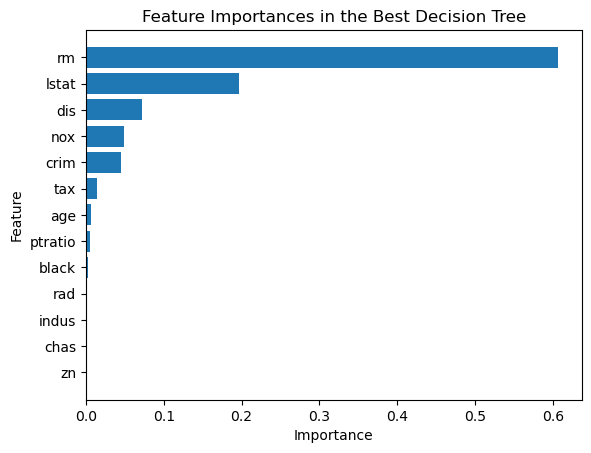

In [9]:
best_tree=DecisionTreeRegressor(min_samples_leaf=1,min_samples_split=2,max_depth=7,random_state=42)
best_tree.fit(X, y)
df_imp = pd.DataFrame({"feature": X.columns, "importance": best_tree.feature_importances_})
df_imp = df_imp.sort_values("importance")
import matplotlib.pyplot as plt
plt.barh(df_imp["feature"], df_imp["importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importances in the Best Decision Tree")
plt.show()

# Concrete Strength

In [12]:
concrete=pd.read_csv("D:\Machine Learning\Datasets\Cases\Concrete_Strength\Concrete_Data.csv")
concrete

,Cement,Blast,Fly,Water,Superplasticizer,Coarse,Fine,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
...,...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.18
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.70
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.77


In [14]:
X=boston.drop('Strength',axis=1)
y=boston['Strength']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Hyper Parameter Tuning

In [15]:

from tqdm import tqdm


depths = [None, 3, 4, 5, 6, 7]
min_samples = [0.01, 2, 10, 50, 100, 250]
min_leafs = [1, 10, 50, 100, 250]
scores = []
for depth in tqdm(depths):
    for min_sample in min_samples:
        for min_leaf in min_leafs:
            dtr = DecisionTreeRegressor(max_depth=depth, 
                                         min_samples_split=min_sample, 
                                         min_samples_leaf=min_leaf, 
                                         random_state=25)
            dtr.fit(X_train, y_train)
            y_pred = dtr.predict(X_test)
            scores.append([depth, min_sample, min_leaf, mean_absolute_error(y_test, y_pred),
                           mean_squared_error(y_test, y_pred),r2_score(y_test, y_pred)])
df_scores = pd.DataFrame(scores, columns=["max_depth", "min_samples_split", "min_samples_leaf", "MSE","MAE","R2_score"])
df_scores.sort_values("MSE")

100%|██████████| 6/6 [00:00<00:00,  6.94it/s]


,max_depth,min_samples_split,min_samples_leaf,MSE,MAE,R2_score
5,NaN,2.00,1,4.237330,41.717244,0.838103
0,NaN,0.01,1,4.753173,47.736829,0.814742
10,NaN,10.00,1,4.754073,46.789735,0.818417
155,7.0,2.00,1,5.397433,57.009554,0.778756
150,7.0,0.01,1,5.521922,57.972180,0.775020
...,...,...,...,...,...,...
149,6.0,250.00,250,11.366356,192.918350,0.251317
174,7.0,100.00,250,11.366356,192.918350,0.251317
169,7.0,50.00,250,11.366356,192.918350,0.251317
164,7.0,10.00,250,11.366356,192.918350,0.251317


Best Tree via Importance for feature

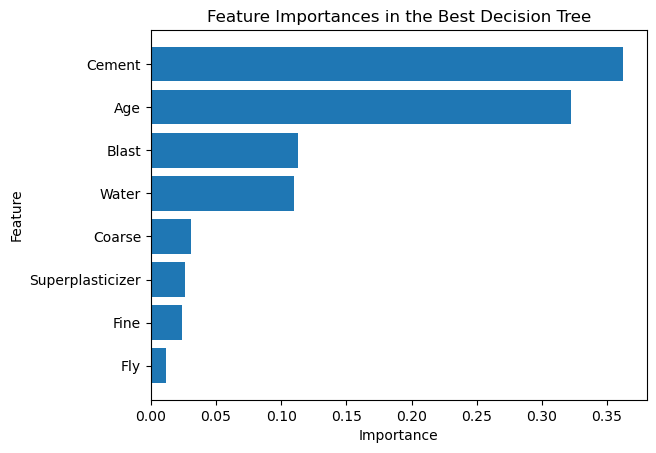

In [17]:
best_tree=DecisionTreeRegressor(min_samples_leaf=1,min_samples_split=2,random_state=42)
best_tree.fit(X, y)
df_imp = pd.DataFrame({"feature": X.columns, "importance": best_tree.feature_importances_})
df_imp = df_imp.sort_values("importance")
import matplotlib.pyplot as plt
plt.barh(df_imp["feature"], df_imp["importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importances in the Best Decision Tree")
plt.show()